# Ensembles and Explainability for Crop Yield Prediction
**BTech Machine Learning Lab - Nidhish Bansal and Yash Vishnoi**

The Advanced Models notebook compared single models (Extra Trees, Histogram Gradient Boosting and a neural network). This notebook asks two follow-up questions:

1. **Can we do better by combining models?** (ensembles)
2. **Can we explain *why* a model predicts a particular yield?** (SHAP explainability)

The target is still **hg/ha_yield** (hectograms per hectare; divide by 10,000 for tonnes/hectare), predicted from country, crop, year, rainfall, pesticide use and temperature.

The code lives in two project modules so the notebook stays short:

| Module | What it does |
|---|---|
| `ensemble_models.py` | Builds the 3 base models and 3 ensembles, runs the time-based experiment |
| `explainability.py` | Computes SHAP values and draws the explanation plots |

Run all cells from top to bottom with the project's Python environment (it needs the `shap` package). The full run takes a few minutes.

## 1. Why ensembles, why explainability, and how we test

### Why ensembles?
Every model makes mistakes, but different kinds of model make **different** mistakes. Extra Trees averages many random decision trees, gradient boosting builds trees one after another to fix earlier errors, and the neural network learns smooth functions. If their errors are not perfectly correlated, some of them cancel out when we combine the predictions. We try three ways of combining:

| Ensemble | How it combines the 3 base models |
|---|---|
| **Simple Average** | Every model gets weight 1/3 |
| **Weighted Average** | Weight proportional to 1 / (validation RMSE)$^2$ - a better model gets more say |
| **Stacking** | A small linear regression (the *meta-model*) **learns** the best combination from out-of-fold predictions |

### Why explainability?
A low error tells us the model is accurate, but not **what it has learned**. A farmer, an examiner or a policy maker will ask: *"Why does the model predict 30 t/ha for this row?"* SHAP answers this by splitting every prediction into a contribution from each input feature. It also lets us check that the model relies on sensible inputs (crop type, country) rather than something accidental.

### The time-based protocol
We are predicting **later years from earlier years**, so time always moves forward:

| Stage | Fit on | Evaluate on | Used for |
|---|---|---|---|
| Validation | 1990-2005 | 2006-2009 | Choosing ensemble weights, comparing models |
| Stacking folds | expanding windows inside the training years | the next 2-year block | Training the meta-model on honest (out-of-fold) predictions |
| Final test | 1990-2009 | **2010-2013** | Reporting the final scores only |

**Why the test years never set the weights:** if we chose the weights (or the meta-model) by looking at 2010-2013, the test score would partly measure how well we fitted the test set, and it would be over-optimistic. A real future year is unknown when the model is built, so the test years must stay untouched until the very end. `run_experiment` contains an `assert` that checks no year after 2009 enters the development data.

In [1]:
import contextlib
import io
from time import perf_counter
import random
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

import ensemble_models as em
import explainability as xai

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

%config InlineBackend.figure_formats = ["png"]
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
COLORS = ["#147d92", "#d49c28", "#6a60a9", "#738579", "#c4553b", "#3d8a4f"]


def show(fig):
    # Display a figure exactly once (the helper functions never call plt.show()).
    display(fig)
    plt.close(fig)


def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


notebook_start = perf_counter()

## 2. Run the experiment
`run_experiment()` does everything in one call:

1. **Validation phase:** fit the 3 base models on 1990-2005, measure RMSE on 2006-2009, compute the weighted-average weights from these RMSEs, and evaluate all 6 models on 2006-2009.
2. **Test phase:** refit everything on 1990-2009 (stacking builds its out-of-fold predictions from 2-year blocks 2002-2003, ..., 2008-2009) and score all 6 models on 2010-2013.

This cell takes about two minutes.

In [2]:
start = perf_counter()
output = em.run_experiment(verbose=True)
experiment_seconds = perf_counter() - start

results = output["results"]
fitted = output["fitted"]
x_train, y_train = output["x_train"], output["y_train"]
x_test, y_test = output["x_test"], output["y_test"]
print(f"\nExperiment finished in {experiment_seconds:.0f} s")

Validation phase: train 1990-2005 (18,262 rows), validate 2006-2009 (4,971 rows)
  fitting Extra Trees ...


  fitting Histogram Gradient Boosting ...


  fitting Neural Network (MLP) ...


  fitting Stacking (validation folds) ...


Test phase: train 1990-2009 (23,233 rows), test 2010-2013 (5,009 rows)
  fitting Extra Trees ...


  fitting Histogram Gradient Boosting ...


  fitting Neural Network (MLP) ...


  fitting Stacking (default folds) ...


Total runtime: 125.2 s

Experiment finished in 125 s


In [3]:
table = results.copy()
table["Test R2"] = table["Test R2"].round(4)
display(
    table.style.format({"Validation RMSE": "{:,.0f}", "Test MAE": "{:,.0f}",
                        "Test RMSE": "{:,.0f}", "Test R2": "{:.4f}"})
         .highlight_min(subset=["Validation RMSE", "Test RMSE", "Test MAE"], color="#cde8e6")
         .hide(axis="index")
)
print("Errors are in hg/ha (10,000 hg/ha = 1 t/ha). Sorted by validation RMSE.")

Model,Type,Validation RMSE,Test MAE,Test RMSE,Test R2
Stacking,Ensemble,"15,616","9,273","18,270",0.9634
Extra Trees,Base,"16,102","10,153","19,943",0.9564
Weighted Average,Ensemble,"16,688","10,049","18,655",0.9619
Simple Average,Ensemble,"17,024","10,327","18,819",0.9612
Neural Network (MLP),Base,"18,662","11,222","19,397",0.9588
Histogram Gradient Boosting,Base,"20,920","13,459","23,347",0.9403


Errors are in hg/ha (10,000 hg/ha = 1 t/ha). Sorted by validation RMSE.


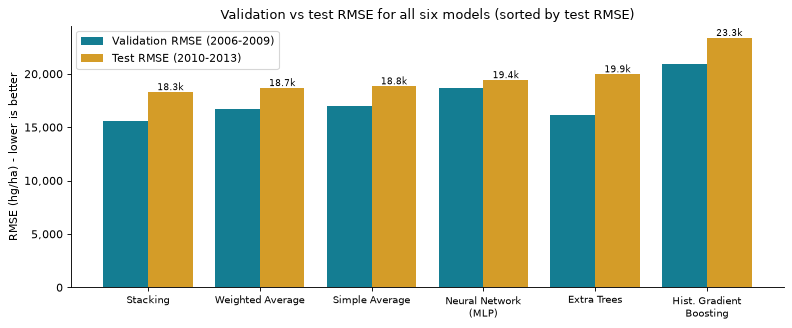

In [4]:
order = results.sort_values("Test RMSE")
positions = np.arange(len(order))
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(positions - 0.2, order["Validation RMSE"], 0.4, label="Validation RMSE (2006-2009)", color=COLORS[0])
ax.bar(positions + 0.2, order["Test RMSE"], 0.4, label="Test RMSE (2010-2013)", color=COLORS[1])
for p, v in zip(positions, order["Test RMSE"]):
    ax.text(p + 0.2, v, f"{v/1000:,.1f}k", ha="center", va="bottom", fontsize=8)
ax.set_xticks(positions)
ax.set_xticklabels([n.replace(" (MLP)", "\n(MLP)").replace("Histogram Gradient Boosting", "Hist. Gradient\nBoosting")
                    for n in order["Model"]], fontsize=9)
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _p: f"{v:,.0f}"))
ax.set_ylabel("RMSE (hg/ha) - lower is better")
ax.set_title("Validation vs test RMSE for all six models (sorted by test RMSE)")
ax.legend()
fig.tight_layout()
show(fig)

In [5]:
rmse_of = results.set_index("Model")
ensembles = rmse_of[rmse_of["Type"] == "Ensemble"]
best_val_ensemble = ensembles["Validation RMSE"].idxmin()
best_test_ensemble = ensembles["Test RMSE"].idxmin()
et_rmse = rmse_of.loc["Extra Trees", "Test RMSE"]

print(f"Best single model on validation : {rmse_of[rmse_of.Type == 'Base']['Validation RMSE'].idxmin()}")
print(f"Best ensemble on validation      : {best_val_ensemble}")
print(f"Best ensemble on test            : {best_test_ensemble}")
for name in ensembles.index:
    gain = et_rmse - rmse_of.loc[name, "Test RMSE"]
    print(f"  {name:17s} test RMSE {rmse_of.loc[name, 'Test RMSE']:>9,.0f}  "
          f"vs Extra Trees {et_rmse:,.0f}: {gain:+,.0f} hg/ha ({100 * gain / et_rmse:+.1f}%)")

Best single model on validation : Extra Trees
Best ensemble on validation      : Stacking
Best ensemble on test            : Stacking
  Stacking          test RMSE    18,270  vs Extra Trees 19,943: +1,672 hg/ha (+8.4%)
  Weighted Average  test RMSE    18,655  vs Extra Trees 19,943: +1,287 hg/ha (+6.5%)
  Simple Average    test RMSE    18,819  vs Extra Trees 19,943: +1,124 hg/ha (+5.6%)


**What the results show**

- **Stacking is the best model on both periods**: validation RMSE 15,616 and test RMSE **18,270 hg/ha** (test R² 0.9634). Extra Trees, the best single model, has test RMSE 19,943, so stacking reduces the test RMSE by **1,672 hg/ha (8.4%)**. The test MAE also falls from 10,153 to 9,273.
- **All three ensembles beat every single model on the test years.** Even the plain Simple Average (18,819) beats Extra Trees, although on validation it looked worse (17,024 vs 16,102). Extra Trees lost the most when moving from validation to test (16,102 -> 19,943); the ensembles were more stable.
- **The Weighted Average validation score (16,688) is slightly optimistic.** Its weights were computed from the same 2006-2009 errors that we then use to score it, so it has had a small "peek" at those years. Only its test score is fully honest. (The stacking validation score does not have this problem: in the validation phase its meta-model was trained only on out-of-fold blocks up to 2005.)
- The Histogram Gradient Boosting model is the weakest base model on both periods (test RMSE 23,347).
- We selected Stacking because it had the **lowest validation RMSE**; the test years only confirm the choice, they did not make it.

The gains are real but moderate: an RMSE of 18,270 hg/ha is about 1.8 t/ha, while yields range from below 1 t/ha to about 50 t/ha.

## 3. Inside the ensembles

### 3.1 Weighted-average weights
Weights are proportional to $1/\text{RMSE}^2$ on the validation years (inverse-variance weighting), then scaled to sum to 1. A model with half the RMSE gets four times the weight.

In [6]:
val_rmse_base = rmse_of.loc[em.BASE_MODEL_NAMES, "Validation RMSE"]
weights_table = pd.DataFrame({
    "Validation RMSE": val_rmse_base,
    "1 / RMSE^2 (x1e-9)": 1e9 / val_rmse_base ** 2,
    "Weight": pd.Series(output["weights"]),
})
display(weights_table.style.format({"Validation RMSE": "{:,.0f}", "1 / RMSE^2 (x1e-9)": "{:.3f}", "Weight": "{:.3f}"}))

,Validation RMSE,1 / RMSE^2 (x1e-9),Weight
Extra Trees,"16,102",3.857,0.428
Histogram Gradient Boosting,"20,920",2.285,0.254
Neural Network (MLP),"18,662",2.871,0.319


### 3.2 Stacking coefficients
The meta-model is `LinearRegression(positive=True)`:

$$\hat y_{\text{stack}} = b + w_1\,\hat y_{\text{ET}} + w_2\,\hat y_{\text{HGB}} + w_3\,\hat y_{\text{MLP}}, \qquad w_i \ge 0$$

It is trained on **out-of-fold** predictions: for each 2-year block (2002-03, 2004-05, 2006-07, 2008-09) the base models are trained only on the *earlier* years and then predict that block. So the meta-model sees honest, "future-like" errors, not the almost-perfect predictions a model makes on its own training rows.

`positive=True` means a coefficient can never be negative. Without it, the regression could give one model a large positive weight and a correlated model a large negative weight - this fits the past slightly better but is unstable and hard to interpret ("subtract the boosting model"?). With the constraint, each coefficient reads as "how much of this model's opinion to use". The weights are **not** forced to sum to 1, and the intercept $b$ can correct an overall bias.

In [7]:
coef = pd.Series(output["stacking_coef"])
display(coef.to_frame("Stacking meta-model").style.format("{:.4f}"))
print(f"Sum of the three model coefficients: {coef.drop('intercept').sum():.4f}")

# Why does a model get 0?  Refit the meta-model WITHOUT the constraint on the same OOF predictions.
stack = fitted["Stacking"]
oof, oof_target = stack.oof_predictions_, stack.oof_target_
free = LinearRegression().fit(oof, oof_target)
compare = pd.DataFrame({"positive=True": stack.meta_model_.coef_, "unconstrained": free.coef_}, index=oof.columns)
display(compare.style.format("{:.4f}"))
print("Out-of-fold RMSE of each base model (2002-2009 blocks):")
for name in oof.columns:
    print(f"  {name:28s} {rmse(oof_target, oof[name]):>9,.0f}")
print("Correlation of out-of-fold ERRORS between base models:")
display((oof.sub(oof_target, axis=0)).corr().round(3))

,Stacking meta-model
Extra Trees,0.8156
Histogram Gradient Boosting,0.0000
Neural Network (MLP),0.2081
intercept,618.1492


Sum of the three model coefficients: 1.0237


,positive=True,unconstrained
Extra Trees,0.8156,0.9088
Histogram Gradient Boosting,0.0000,-0.1117
Neural Network (MLP),0.2081,0.2220


Out-of-fold RMSE of each base model (2002-2009 blocks):
  Extra Trees                     13,818
  Histogram Gradient Boosting     19,231
  Neural Network (MLP)            15,697
Correlation of out-of-fold ERRORS between base models:


,Extra Trees,Histogram Gradient Boosting,Neural Network (MLP)
Extra Trees,1.000,0.781,0.728
Histogram Gradient Boosting,0.781,1.000,0.614
Neural Network (MLP),0.728,0.614,1.000


**Reading the stacking coefficients**

- Extra Trees gets **0.816**, the MLP **0.208** and Histogram Gradient Boosting exactly **0**. The intercept is only 618 hg/ha and the coefficients sum to 1.024, so the meta-model is almost a weighted average: "about 80% Extra Trees + 20% neural network".
- **Why does HistGB get 0?** On the out-of-fold blocks it is clearly the weakest model (OOF RMSE 19,231 vs 13,818 for Extra Trees and 15,697 for the MLP), and its errors are strongly correlated with the Extra Trees errors (0.781). It therefore brings little new information. Without the constraint the regression would actually give it a **negative** weight (-0.112), i.e. "subtract a bit of HistGB". `positive=True` forbids negative weights, so the best allowed value is the boundary value 0 - HistGB is simply dropped.
- The MLP keeps a useful weight because its errors are the **least** correlated with the others (0.728 with Extra Trees, 0.614 with HistGB): it makes different mistakes, so it adds diversity.
- Compare with the weighted average, which gave HistGB 0.254: inverse-RMSE weighting looks only at each model's own accuracy, while stacking also takes into account how much the models overlap.

### 3.3 Diversity: how similar are the base models?
An ensemble can only help if the base models disagree sometimes. If two models always made the same prediction, averaging them would change nothing. Below, the left heatmap shows the correlation of the **predictions** on the 2010-2013 test rows, and the right one the correlation of their **errors** (actual - predicted). Prediction correlations are always very high because all models learn that potatoes yield more than wheat; the error correlation is the more useful measure of diversity.

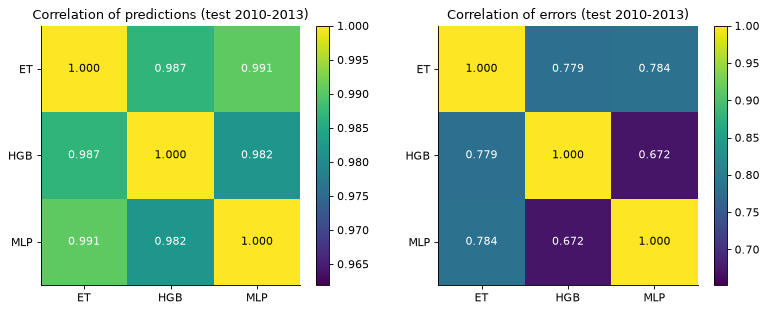

,ET,HGB,MLP
ET,1.000,0.779,0.784
HGB,0.779,1.000,0.672
MLP,0.784,0.672,1.000


In [8]:
base_test = stack.base_predictions(x_test)
errors_test = base_test.rsub(y_test, axis=0)
short = {"Extra Trees": "ET", "Histogram Gradient Boosting": "HGB", "Neural Network (MLP)": "MLP"}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, frame, title in [(axes[0], base_test, "Correlation of predictions"),
                         (axes[1], errors_test, "Correlation of errors")]:
    corr = frame.rename(columns=short).corr()
    im = ax.imshow(corr, cmap="viridis", vmin=corr.values.min() - 0.02, vmax=1)
    ax.set_xticks(range(3)); ax.set_xticklabels(corr.columns)
    ax.set_yticks(range(3)); ax.set_yticklabels(corr.columns)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{corr.iloc[i, j]:.3f}", ha="center", va="center",
                    color="white" if corr.iloc[i, j] < corr.values.mean() else "black")
    ax.set_title(f"{title} (test 2010-2013)")
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
show(fig)
display(errors_test.rename(columns=short).corr().round(3))

**What the heatmaps tell us**

- The predictions are almost identical (correlations 0.982-0.991): all three models agree on the big picture (crop and country decide most of the yield).
- The **errors** are much less correlated (0.672-0.784). This is where an ensemble gains: when one model overshoots and another undershoots, the average lands closer to the truth.
- The least correlated pair is HistGB-MLP (0.672). On the test years Extra Trees is about equally correlated with the other two (0.779 with HGB, 0.784 with MLP), but the MLP is much more accurate than HGB (test RMSE 19,397 vs 23,347), so it is the more useful partner. On the out-of-fold years the MLP was also clearly the more different partner (0.728 vs 0.781). This matches the stacking result: Extra Trees + MLP is the useful combination.

### 3.4 Stacking: predicted vs actual on the test years
Points on the dashed diagonal are perfect predictions. The axes are in tonnes/hectare to keep the numbers readable.

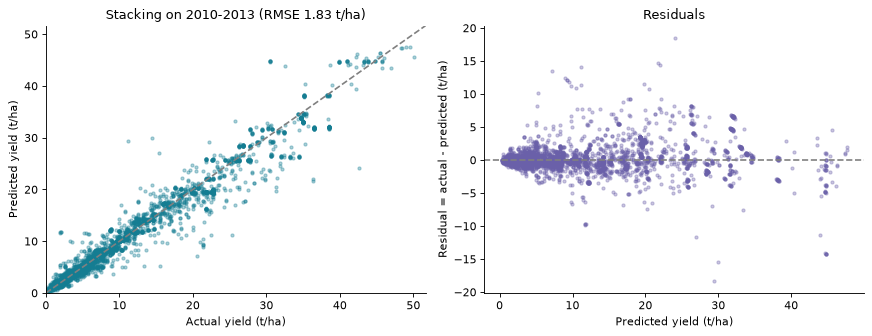

In [9]:
stack_pred = fitted["Stacking"].predict(x_test)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
axes[0].scatter(y_test / 1e4, stack_pred / 1e4, s=8, alpha=0.35, color=COLORS[0])
lim = [0, max(y_test.max(), stack_pred.max()) / 1e4 * 1.03]
axes[0].plot(lim, lim, "--", color="gray")
axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("Actual yield (t/ha)"); axes[0].set_ylabel("Predicted yield (t/ha)")
axes[0].set_title(f"Stacking on 2010-2013 (RMSE {rmse(y_test, stack_pred)/1e4:.2f} t/ha)")
residual = (y_test - stack_pred) / 1e4
axes[1].scatter(stack_pred / 1e4, residual, s=8, alpha=0.35, color=COLORS[2])
axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set_xlabel("Predicted yield (t/ha)"); axes[1].set_ylabel("Residual = actual - predicted (t/ha)")
axes[1].set_title("Residuals")
fig.tight_layout()
show(fig)

Most test rows lie close to the diagonal, and the stacking RMSE is 1.83 t/ha. The residuals fan out as the predicted yield grows: high-yield crops (potatoes, cassava, sweet potatoes) have larger absolute errors, simply because their yields are larger. A few rows are missed by more than 10 t/ha in both directions; one of them (Sorghum in Algeria, 2012) is examined in Section 4.6.

## 4. SHAP explainability

### 4.1 A little theory
SHAP (SHapley Additive exPlanations) comes from cooperative game theory. Think of the 6 input features as players in a team and the prediction as the team's score. The **Shapley value** of a feature is its average extra contribution to the prediction, averaged over every order in which the features could join the team. "Removing" a feature is simulated by replacing its value with values from a **background** sample of real rows.

The key property is **additivity (local accuracy)**:

$$\text{prediction} = \underbrace{\text{base value}}_{\text{average prediction on the background}} + \sum_{\text{features}} \text{SHAP value}$$

So every SHAP value is in **hg/ha**: "this feature pushed this prediction up (+) or down (-) by so many hg/ha".

We use two explainers:

| Model | Explainer | Why |
|---|---|---|
| Extra Trees | `explain_tree_pipeline` (`shap.TreeExplainer`, interventional) | Walks the trees directly - exact and fast. One-hot columns are summed back into "Country" and "Crop". |
| Stacking ensemble | `explain_model` (`shap.explainers.Exact`) | Model-agnostic: only calls `predict`. With 6 features there are just $2^6 = 64$ coalitions, so we compute the *exact* Shapley values. |

**Background choice:** both explainers use rows from the **training years** (1990-2009) as background. For Extra Trees this matters: if the background came from 2010-2013 only, every row would fall on the same side of every Year split (the trees never saw a year after 2009), and Year would always get a SHAP value of exactly 0.

**Sample sizes:** the exact explainer costs 64 coalitions x 50 background rows = 3,200 ensemble predictions per explained row, so we explain a random sample of **120 test rows** (seed 42). Extra Trees is explained on the same rows so the two models can be compared fairly.

In [10]:
N_EXPLAIN = 120
X_explain = x_test.sample(n=N_EXPLAIN, random_state=SEED)
y_explain = y_test.loc[X_explain.index]
X_background = x_train.sample(n=50, random_state=SEED)   # 50 rows from 1990-2009

et_model = fitted["Extra Trees"]
stack_model = fitted["Stacking"]

start = perf_counter()
with contextlib.redirect_stderr(io.StringIO()):   # hide shap's progress bar
    shap_et = xai.explain_tree_pipeline(et_model, X_explain, X_background=x_train, n_background=100, seed=SEED)
et_seconds = perf_counter() - start

start = perf_counter()
shap_stack = xai.explain_model(stack_model, X_background, X_explain, seed=SEED)
stack_seconds = perf_counter() - start

print(f"Extra Trees SHAP : {N_EXPLAIN} rows in {et_seconds:5.1f} s  (base value {shap_et.base_values[0]:,.0f} hg/ha)")
print(f"Stacking SHAP    : {N_EXPLAIN} rows in {stack_seconds:5.1f} s  (base value {shap_stack.base_values[0]:,.0f} hg/ha)")

Extra Trees SHAP : 120 rows in  11.8 s  (base value 80,414 hg/ha)
Stacking SHAP    : 120 rows in  31.4 s  (base value 78,171 hg/ha)


### 4.2 Proof that the explanations are correct (additivity check)
For every explained row we rebuild the prediction as base value + sum of SHAP values and compare it with the model's real prediction. The maximum error should be essentially zero (a yield is around 10,000-500,000 hg/ha, so an error below 1 hg/ha is negligible).

In [11]:
pred_et = et_model.predict(X_explain)
pred_stack = stack_model.predict(X_explain)
print(f"Extra Trees : max |base + sum(SHAP) - prediction| = {xai.additivity_error(shap_et, pred_et):.2e} hg/ha")
print(f"Stacking    : max |base + sum(SHAP) - prediction| = {xai.additivity_error(shap_stack, pred_stack):.2e} hg/ha")

Extra Trees : max |base + sum(SHAP) - prediction| = 1.10e-02 hg/ha
Stacking    : max |base + sum(SHAP) - prediction| = 4.66e-10 hg/ha


### 4.3 Global importance: which features matter most?
**Mean |SHAP|** = on average, how many hg/ha a feature moves a prediction (in either direction). Unlike permutation importance it is measured directly in yield units.

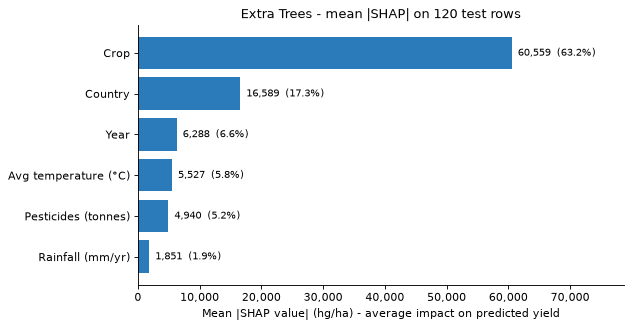

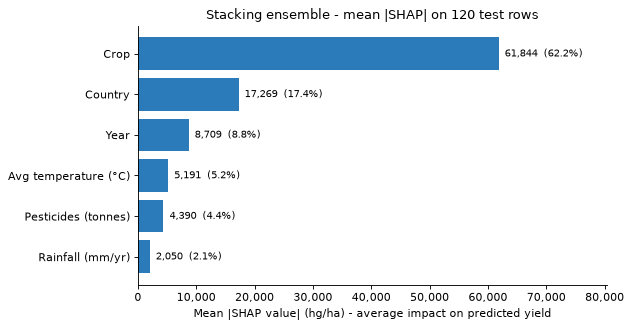

In [12]:
show(xai.plot_importance(shap_et, title="Extra Trees - mean |SHAP| on 120 test rows"))
show(xai.plot_importance(shap_stack, title="Stacking ensemble - mean |SHAP| on 120 test rows"))

In [13]:
imp_et = xai.shap_importance_table(shap_et).set_index("Feature")
imp_stack = xai.shap_importance_table(shap_stack).set_index("Feature")
side_by_side = pd.concat({"Extra Trees": imp_et, "Stacking": imp_stack}, axis=1)
side_by_side = side_by_side.sort_values(("Stacking", "Share (%)"), ascending=False)
display(side_by_side.style.format("{:,.1f}"))

**What the importance tells us**

- **Crop dominates.** It moves a prediction by about 61,800 hg/ha on average for the stacking ensemble (62.2% of the total) and 60,600 hg/ha (63.2%) for Extra Trees. This makes sense: a potato field yields far more hg/ha than a soybean field, whatever the weather.
- **Country is second** (about 17% for both models). Country stands for everything the dataset does not record directly: soil, irrigation, technology, farming practice.
- **Year comes third** (8.8% stacking, 6.6% Extra Trees): the models have learned that yields tend to rise over time.
- **The weather and pesticide features matter least**: temperature about 5%, pesticides 4-5%, rainfall only about 2% (2,050 hg/ha on average for stacking).
- The two models agree on the ranking and on most numbers, which is expected because the stacking ensemble is about 80% Extra Trees. The ensemble puts a little more weight on Year; a plausible reason is its 20% neural-network part, which (unlike trees) can keep a trend going beyond the last training year 2009, but we did not test this separately.

### 4.4 Beeswarm: direction of the numeric effects
Each dot is one test row. Its horizontal position is the SHAP value (push up or down) and its colour is the feature value (red = high, blue = low). Country and Crop have no "high/low", so they are left out of this plot (their importance is shown above).

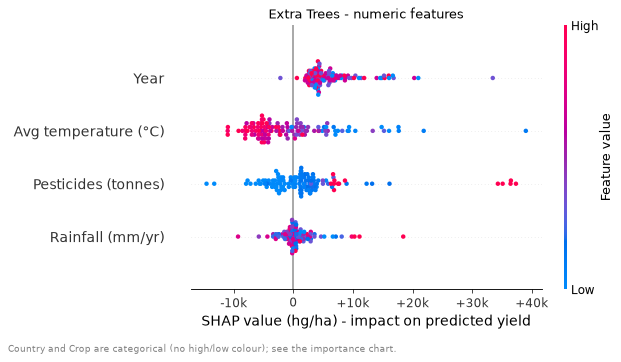

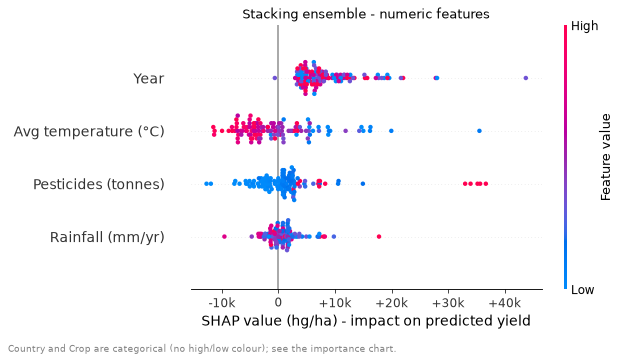

In [14]:
show(xai.plot_beeswarm(shap_et, title="Extra Trees - numeric features"))
show(xai.plot_beeswarm(shap_stack, title="Stacking ensemble - numeric features"))

**What the beeswarm shows**

- **Year** pushes almost every test prediction **up** (from -647 to +43,764 hg/ha for stacking). The test rows are from 2010-2013, later than every background row, and the models learned that later years have higher yields.
- **Temperature**: red dots (hot) are mostly on the left (lower prediction) and blue dots (cool) on the right. Cooler countries get higher predictions.
- **Pesticides**: most rows are near zero, but a small group of red dots (very high pesticide use) is pushed up by more than +30,000 hg/ha.
- **Rainfall** stays in a narrow band around zero for most rows: the model hardly uses it.

### 4.5 Dependence plots: rainfall, temperature and pesticides
A dependence plot shows the SHAP value of one feature against the feature's value, coloured by crop. A flat cloud around zero means the model barely uses that feature; a clear trend shows how the prediction changes as the feature grows. These plots are for the **Stacking ensemble**.

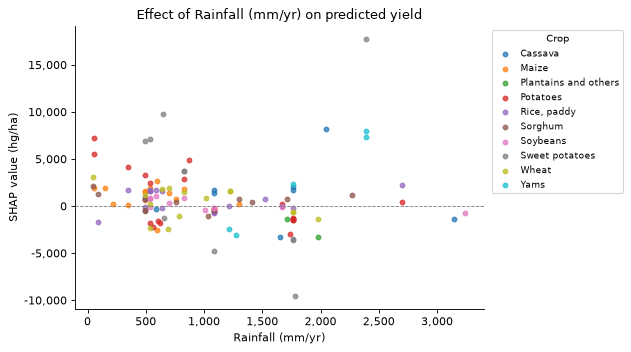

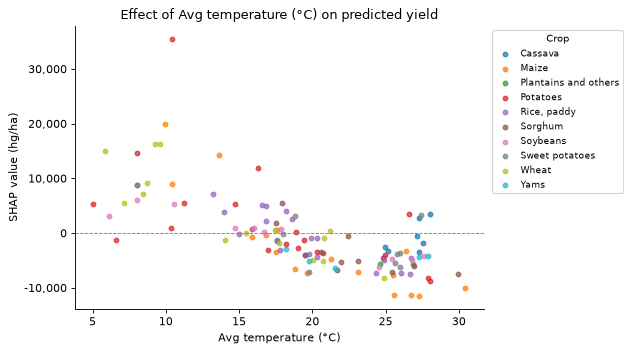

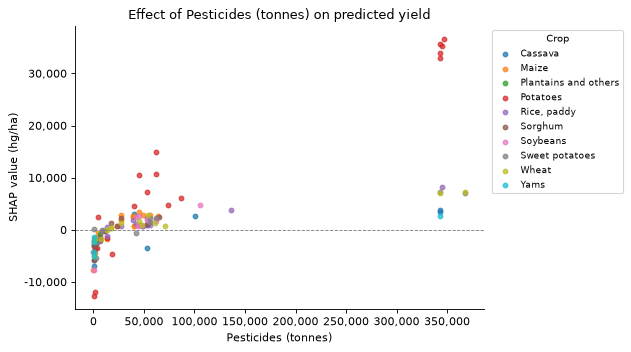

In [15]:
for feature in ["average_rain_fall_mm_per_year", "avg_temp", "pesticides_tonnes"]:
    show(xai.plot_dependence(shap_stack, feature))

In [16]:
# Numbers behind the dependence plots: spread of each numeric feature's SHAP values (Stacking).
num_idx = {f: xai.FEATURES.index(f) for f in ["Year", "average_rain_fall_mm_per_year", "avg_temp", "pesticides_tonnes"]}
spread = pd.DataFrame({
    xai.FEATURE_LABELS[f]: {
        "min SHAP": shap_stack.values[:, j].min(),
        "max SHAP": shap_stack.values[:, j].max(),
        "corr(value, SHAP)": np.corrcoef(shap_stack.data[:, j].astype(float), shap_stack.values[:, j])[0, 1],
    }
    for f, j in num_idx.items()
}).T
display(spread.style.format({"min SHAP": "{:,.0f}", "max SHAP": "{:,.0f}", "corr(value, SHAP)": "{:+.2f}"}))

,min SHAP,max SHAP,"corr(value, SHAP)"
Year,-647,"43,764",-0.13
Rainfall (mm/yr),"-9,563","17,787",-0.07
Avg temperature (°C),"-11,531","35,554",-0.71
Pesticides (tonnes),"-12,731","36,689",+0.72


**What the dependence plots show (Stacking ensemble)**

- **Rainfall:** no clear trend (correlation between rainfall and its SHAP value is only -0.07). Most SHAP values lie within about ±5,000 hg/ha. Annual average rainfall for a whole country says little about the yield of a particular crop.
- **Temperature:** a clear downward trend (correlation -0.71). Below about 12 °C the effect is mostly positive (up to +35,554 hg/ha, for potatoes in France); above about 25 °C it is mostly negative (down to -11,531). Remember that temperature is fixed per country, so this partly reflects *which* countries are cool (e.g. European countries with high-yield farming), not only the effect of heat on plants.
- **Pesticides:** an upward trend (correlation +0.72). Countries with very low pesticide use get small negative values, and the rows above 300,000 tonnes - all from Brazil, the only country in the dataset with that much pesticide use - get the largest positive values, especially potatoes (about +35,000 hg/ha). Pesticide tonnes are a national total, so this mostly identifies a large agricultural country rather than measuring the benefit of spraying.

### 4.6 Explaining single predictions
A **waterfall** plot starts at the base value $E[f(X)]$ (bottom) and adds one feature at a time until it reaches the prediction $f(x)$ (top). We pick interesting rows from the 120 explained test rows using the Stacking model's error:

* the row with the **largest absolute error**,
* a **typical** row (median absolute error),
* the row with the **highest predicted yield**.

In [17]:
cases = pd.DataFrame({
    "Country": X_explain["Area"].to_numpy(),
    "Crop": X_explain["Item"].to_numpy(),
    "Year": X_explain["Year"].to_numpy(),
    "Actual": y_explain.to_numpy(),
    "Predicted (Stacking)": pred_stack,
})
cases["Error (actual - pred)"] = cases["Actual"] - cases["Predicted (Stacking)"]
abs_err = cases["Error (actual - pred)"].abs()
picks = {
    "Largest error": int(abs_err.idxmax()),
    "Typical (median error)": int((abs_err - abs_err.median()).abs().idxmin()),
    "Highest prediction": int(cases["Predicted (Stacking)"].idxmax()),
}
chosen = cases.loc[list(picks.values())].copy()
chosen.insert(0, "Case", list(picks.keys()))
display(chosen.style.format({"Actual": "{:,.0f}", "Predicted (Stacking)": "{:,.0f}",
                             "Error (actual - pred)": "{:+,.0f}"}).hide(axis="index"))

Case,Country,Crop,Year,Actual,Predicted (Stacking),Error (actual - pred)
Largest error,Algeria,Sorghum,2012,"206,000","71,899","+134,101"
Typical (median error),Japan,Soybeans,2013,"15,520","19,139","-3,619"
Highest prediction,France,Potatoes,2010,"421,566","436,415","-14,849"


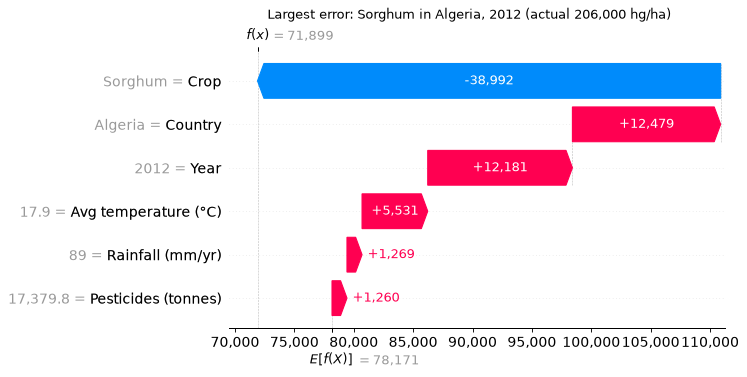

[Largest error] Stacking: Starting from the average prediction of 78,171 hg/ha, Crop = Sorghum lowered it by -38,992; Country = Algeria raised it by +12,479; Year = 2012 raised it by +12,181; Avg temperature (°C) = 17.9 raised it by +5,531; Rainfall (mm/yr) = 89 raised it by +1,269; Pesticides (tonnes) = 17,379.8 raised it by +1,260 - giving a predicted yield of 71,899 hg/ha.
[Largest error] Extra Trees: Starting from the average prediction of 80,414 hg/ha, Crop = Sorghum lowered it by -37,963; Country = Algeria raised it by +10,446; Year = 2012 raised it by +9,164; Avg temperature (°C) = 17.9 raised it by +5,774; Rainfall (mm/yr) = 89 raised it by +1,822; Pesticides (tonnes) = 17,379.8 raised it by +1,762 - giving a predicted yield of 71,419 hg/ha.



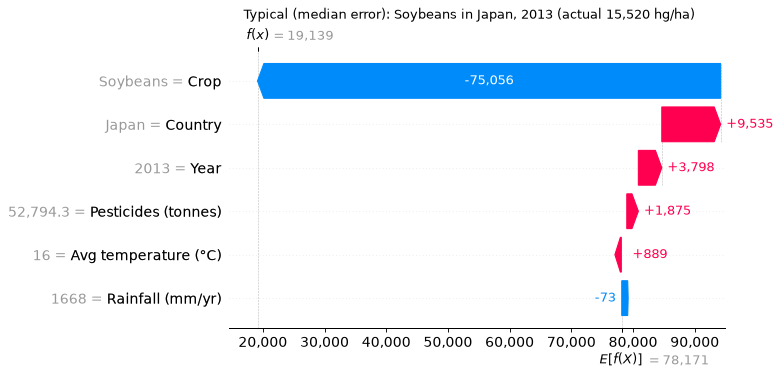

[Typical (median error)] Stacking: Starting from the average prediction of 78,171 hg/ha, Crop = Soybeans lowered it by -75,056; Country = Japan raised it by +9,535; Year = 2013 raised it by +3,798; Pesticides (tonnes) = 52,794.3 raised it by +1,875; Avg temperature (°C) = 16 raised it by +889; Rainfall (mm/yr) = 1668 lowered it by -73 - giving a predicted yield of 19,139 hg/ha.
[Typical (median error)] Extra Trees: Starting from the average prediction of 80,414 hg/ha, Crop = Soybeans lowered it by -76,988; Country = Japan raised it by +8,214; Pesticides (tonnes) = 52,794.3 raised it by +2,348; Year = 2013 raised it by +2,015; Avg temperature (°C) = 16 raised it by +1,223; Rainfall (mm/yr) = 1668 lowered it by -189 - giving a predicted yield of 17,038 hg/ha.



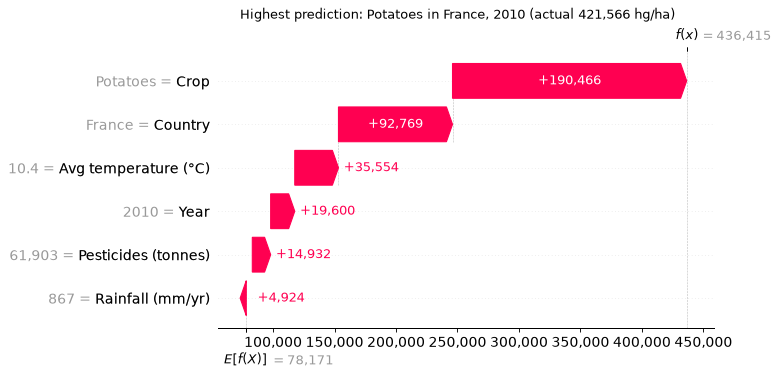

[Highest prediction] Stacking: Starting from the average prediction of 78,171 hg/ha, Crop = Potatoes raised it by +190,466; Country = France raised it by +92,769; Avg temperature (°C) = 10.4 raised it by +35,554; Year = 2010 raised it by +19,600; Pesticides (tonnes) = 61,903 raised it by +14,932; Rainfall (mm/yr) = 867 raised it by +4,924 - giving a predicted yield of 436,415 hg/ha.
[Highest prediction] Extra Trees: Starting from the average prediction of 80,414 hg/ha, Crop = Potatoes raised it by +178,788; Country = France raised it by +90,610; Avg temperature (°C) = 10.4 raised it by +39,008; Pesticides (tonnes) = 61,903 raised it by +16,133; Year = 2010 raised it by +14,580; Rainfall (mm/yr) = 867 raised it by +4,650 - giving a predicted yield of 424,183 hg/ha.



In [18]:
for label, i in picks.items():
    row = cases.loc[i]
    title = f"{label}: {row.Crop} in {row.Country}, {row.Year} (actual {row.Actual:,.0f} hg/ha)"
    fig = xai.plot_waterfall(shap_stack, i, title=title)
    fig.axes[0].set_xlabel("")  # avoid overlapping the E[f(X)] label; units are hg/ha
    show(fig)
    print(f"[{label}] Stacking: " + xai.explain_single_prediction(shap_stack, i))
    print(f"[{label}] Extra Trees: " + xai.explain_single_prediction(shap_et, i))
    print()

**Reading the individual explanations**

- **Largest error - Sorghum in Algeria, 2012:** actual 206,000 hg/ha, predicted 71,899 (error +134,101). The explanation is sensible: "Sorghum" pulls the prediction down by about 39,000 because sorghum is normally a low-yield crop, while Algeria, the later year and the temperature push it up. The actual value is the problem: 206,000 hg/ha (20.6 t/ha) is the **highest sorghum yield in the whole dataset**, and the Algerian sorghum series jumps around a lot (30,286 in 2010, 100,000 in 2011, 206,000 in 2012, 60,000 in 2013). No model could predict this from the six inputs; it may be a reporting artefact. SHAP helps us see that the model behaved reasonably and the row is unusual.
- **Typical row - Soybeans in Japan, 2013:** actual 15,520, predicted 19,139 (error -3,619). Almost the whole explanation is the crop: "Soybeans" lowers the prediction by about 75,000 from the base value of 78,171; Japan adds about 9,500 and the other features very little.
- **Highest prediction - Potatoes in France, 2010:** actual 421,566, predicted 436,415. Potatoes (+190,466) and France (+92,769) explain most of it, and the cool temperature (+35,554) adds a large amount too.
- Extra Trees gives very similar stories for the same rows (e.g. Soybeans -76,988, Potatoes +178,788), because it is the largest part of the ensemble.
- In every case base value + contributions equals the prediction exactly (the additivity check in 4.2 gave errors of 0.011 hg/ha for Extra Trees and about 5e-10 hg/ha for stacking).

In [19]:
print(f"Total notebook runtime: {perf_counter() - notebook_start:.0f} s")

Total notebook runtime: 171 s


## 5. Limitations
- **SHAP explains the model, not the world.** A positive SHAP value for rainfall means *the model* raises its prediction when rainfall is high. It does not prove that more rain causes higher yield. Only a controlled experiment (or a causal analysis) can show that.
- **Correlated features share credit unpredictably.** Rainfall, temperature and pesticide use are recorded per country, so they are strongly tied to the Country feature. The model may "explain" a country effect through rainfall or the other way round, and the split between correlated features depends on the background data.
- **The background sample changes the numbers.** The base value and individual SHAP values depend on the 50/100 background rows. The broad ranking of features is stable, but exact values would shift with another sample.
- **Only a sample was explained.** Exact Shapley values for the ensemble cost 3,200 predictions per row, so we explained 120 of the 2010-2013 rows.
- **Coarse inputs.** Rainfall and temperature are country-level annual averages; pesticides are national totals in tonnes. They cannot capture a drought in the growing season, irrigation, soil quality, or crop variety, so their measured effect is small.
- **Ensembles add cost.** The ensemble needs three models to be trained and stored, and stacking needs extra out-of-fold training. The gain must be judged against this cost.
- **One time split.** All scores come from one validation period (2006-2009) and one test period (2010-2013); another period could rank the models differently.

## 6. Viva questions

1. **What is an ensemble and why can it beat its best member?**
   It combines several models' predictions. If their errors are not perfectly correlated, some errors cancel out. Here the error correlations were only 0.67-0.78, and stacking reduced test RMSE from 19,943 (Extra Trees) to 18,270.

2. **Difference between simple averaging, weighted averaging and stacking?**
   Simple: equal weights. Weighted: fixed weights from validation RMSE (1/RMSE²). Stacking: a meta-model *learns* the weights (and an intercept) from out-of-fold predictions, so it also accounts for overlap between models.

3. **Why must the meta-model be trained on out-of-fold predictions?**
   Predictions on a model's own training rows are almost perfect, so the meta-model would trust the most overfitted model. Out-of-fold predictions show honest errors, like on new data.

4. **Why expanding time windows instead of ordinary K-fold?**
   We predict the future. Each block (e.g. 2006-2007) is predicted by models trained only on earlier years, so no future information leaks into the past.

5. **Why did Histogram Gradient Boosting get a stacking weight of 0?**
   It was the weakest model and its errors overlap strongly with Extra Trees. Unconstrained regression wanted a negative weight (-0.11); `positive=True` forbids that, so the weight is clipped to 0.

6. **Why are the test years never used to pick weights?**
   Otherwise the test score would partly measure fitting the test set and would be over-optimistic. That is also why the Weighted Average's validation score is slightly optimistic: its weights came from those validation years.

7. **What is a SHAP value and what is additivity?**
   The Shapley value of a feature is its average contribution to a prediction over all orders of adding features. Additivity: base value + sum of SHAP values = prediction. We verified it (max error 0.011 hg/ha for Extra Trees, ~5e-10 for stacking).

8. **Which feature matters most and does that make sense?**
   Crop (about 62% of mean |SHAP|), then Country (17%), Year (7-9%); rainfall only ~2%. Yes: crop types have very different yield scales, and country captures soil, irrigation and technology that are not in the data.

9. **Does a positive SHAP value for pesticides prove pesticides increase yield?**
   No. SHAP describes the model's behaviour, not cause and effect. Pesticide tonnes are a national total, so the high values mainly identify Brazil.

10. **Why use a training-year background for Extra Trees?**
    The trees only split on years up to 2009. With a 2010-2013 background every row would fall on the same side of every Year split, so Year would always get a SHAP value of 0.

11. **Why is the exact explainer possible here?**
    There are only 6 features, so only 2⁶ = 64 feature subsets. We can evaluate all of them and get exact Shapley values instead of an approximation.

**Conclusion:** Combining models helps: stacking (about 80% Extra Trees + 20% neural network) gave the lowest validation and test errors, an 8.4% lower test RMSE than the best single model. SHAP shows that both Extra Trees and the ensemble mainly use crop and country, with a rising trend over years and small, mostly country-level effects of temperature, pesticides and rainfall.